In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from twopoint import twopoint
import plot
from numpy.lib import recfunctions as rfn
import os


In [2]:
fpath = Path("old_runs/giulia_2pt/giulia_2pt_example.fits")
ffile = fits.open(fpath)
del ffile[4:6]
del ffile[-1]

In [3]:
weaklens_dir = Path.cwd().parent.parent
run_dir = weaklens_dir / "clean_sims" / "DELVE" / "respimprint2pt" / "A"


In [4]:
import pickle

npairs_dict = {}

for i in range(0, 4):
    for j in range(0, i + 1):
        pickle_file = run_dir / "results/gg_r{0}{1}.pickle".format(j, i)
        print(pickle_file)
        with open(pickle_file, 'rb') as f:
            gg_data = pickle.load(f)
            npairs_dict[(j + 1, i + 1)] = gg_data.npairs

/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r00.pickle


/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r01.pickle
/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r11.pickle
/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r02.pickle
/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r12.pickle
/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r22.pickle
/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r03.pickle
/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r13.pickle


/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r23.pickle
/home/shrihan/weaklens/clean_sims/DELVE/respimprint2pt/A/results/gg_r33.pickle


In [5]:
cross_xip = {}
cross_xim = {}
theta_corr = {}

# Load the xip and jackknife uncertainty in xip from treecorr for each binning
for i in range(0, 4):
    for j in range(0, i + 1):
        cross_xip[(j + 1, i + 1)] = np.load(run_dir / "results/xip_corr_r{0}{1}.npy".format(j, i))
        cross_xim[(j + 1, i + 1)] = np.load(run_dir / "results/xim_corr_r{0}{1}.npy".format(j, i))
        theta_corr[(j + 1, i + 1)] = np.load(run_dir / "results/theta_corr_r{0}{1}.npy".format(j, i))

In [6]:
# Remove the pixel-scale artefact of the nside-1024 response map (3.4' pixels).
# In the two smallest angular bins (theta < 3.96') use the fiducial xi, i.e. no response imprint there.
# The DES Y3 scale cuts already drop these bins for every pair except (1,1); this cleans (1,1) too.
fid_dir = run_dir.parent.parent / "fiducial2pt" / "A" / "results"
n_pix_bins = 2
for i in range(0, 4):
    for j in range(0, i + 1):
        cross_xip[(j + 1, i + 1)][:n_pix_bins] = np.load(fid_dir / f"xip_corr_r{j}{i}.npy")[:n_pix_bins]
        cross_xim[(j + 1, i + 1)][:n_pix_bins] = np.load(fid_dir / f"xim_corr_r{j}{i}.npy")[:n_pix_bins]
print("replaced bins with fiducial; their theta [arcmin]:", np.round(theta_corr[(1, 1)][:n_pix_bins], 2))

replaced bins with fiducial; their theta [arcmin]: [2.83 3.56]


In [7]:
xip_data = ffile[2].data
xim_data = ffile[3].data

val_xip = np.zeros(10 * 20)
val_xim = np.zeros(10 * 20)
npairs = np.zeros(10 * 20)

for i in range(len(val_xip)):
    val_xip[i] = cross_xip[(xip_data['BIN1'][i], xip_data['BIN2'][i])][xip_data['ANGBIN'][i]]
    val_xim[i] = cross_xim[(xim_data['BIN1'][i], xim_data['BIN2'][i])][xim_data['ANGBIN'][i]]
    npairs[i] = npairs_dict[(xip_data['BIN1'][i], xip_data['BIN2'][i])][xip_data['ANGBIN'][i]]
    
xip_data['VALUE'] = val_xip
xim_data['VALUE'] = val_xim
xip_data['NPAIRS'] = npairs
xim_data['NPAIRS'] = npairs

# Changing the NPAIRS column to 1 doesnt make a diff, but using treecorr output anyway
# xip_data['NPAIRS']  = 1
# xim_data['NPAIRS']  = 1

# Dropping the NPAIRS column causes errors
# xip_b = rfn.drop_fields(xip_data, 'NPAIRS')
# xim_b = rfn.drop_fields(xim_data, 'NPAIRS')

ffile[2].data = xip_data
ffile[3].data = xim_data


In [8]:
!cat ../../cosmocow/covs/output/out_cov_delve_shrihan_fp_rt2_norm_ng/d* > covdata_delve.txt

Dimension of cov: 400x400


Text(0.5, 1.0, 'Final Covariance')

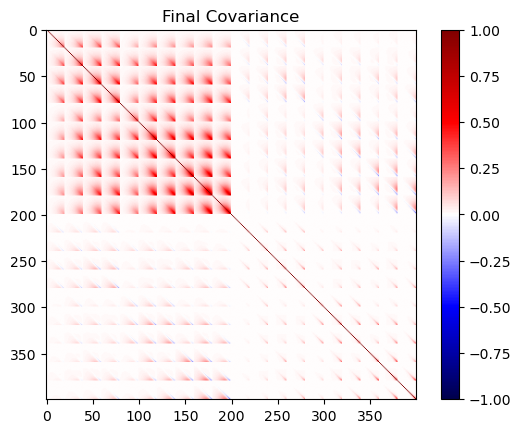

In [9]:
cov_g, cov_ng, ndata = plot.get_cov("covdata_delve.txt")
cov = cov_g + cov_ng
pp_norm = np.zeros((ndata,ndata))
for i in range(ndata):
    for j in range(ndata):
        pp_norm[i][j] = cov[i][j]/ np.sqrt(cov[i][i]*cov[j][j])
        
plt.imshow(pp_norm, cmap = 'seismic', vmin = -1, vmax = 1)
plt.colorbar()
plt.title("Final Covariance")

In [10]:
ffile[1].header.pop('STRT_2', None)
ffile[1].header.pop('NAME_2', None)
ffile[1].header.pop('STRT_3', None)
ffile[1].header.pop('NAME_3', None)
ffile[1].header['NAXIS1'] = 400
ffile[1].header['NAXIS2'] = 400
ffile[1].data = cov

In [11]:
delve_data = run_dir.parent.parent / "DELVE_Data"

ztomo = np.load(delve_data / "ztomo_DELVE.npy")
nztomo = np.load(delve_data / "nztomo_DELVE.npy")

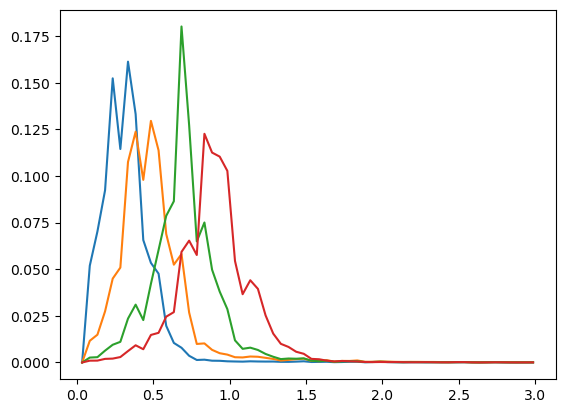

In [12]:
plt.plot(ztomo, nztomo[0], label = 'Source 1')
plt.plot(ztomo, nztomo[1], label = 'Source 2')
plt.plot(ztomo, nztomo[2], label = 'Source 3')
plt.plot(ztomo, nztomo[3], label = 'Source 4')

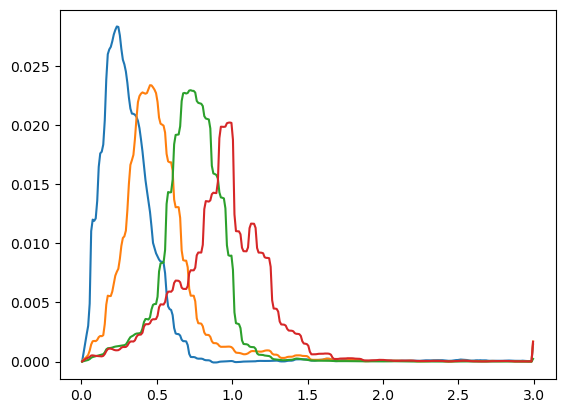

In [13]:
plt.plot(ffile[4].data['Z_MID'], ffile[4].data['BIN1'], label = 'Source 1')
plt.plot(ffile[4].data['Z_MID'], ffile[4].data['BIN2'], label = 'Source 2')
plt.plot(ffile[4].data['Z_MID'], ffile[4].data['BIN3'], label = 'Source 3')
plt.plot(ffile[4].data['Z_MID'], ffile[4].data['BIN4'], label = 'Source 4')

In [14]:
# Number density per bin for DELVE (https://arxiv.org/pdf/2502.17677)
n_density = [1.293, 
             1.150,
             1.169,
             1.153]

sigma_all = [0.233, 0.259, 0.248, 0.289]

zhead = ffile[4].header
zhead['NBIN'] = 4
zhead['NZ'] = 300

for i in range(4):
    zhead[f'NGAL_{i + 1}'] = n_density[i]
for i in range(4):
    zhead[f'SIG_E_{i + 1}'] = sigma_all[i]

zdata = ffile[4].data
z_a = np.recarray(len(ztomo), dtype=zdata.dtype)
z_b = rfn.drop_fields(z_a, 'BIN5')
znew = rfn.drop_fields(z_b, 'BIN6')
del z_a, z_b
znew['Z_MID'] = ztomo
znew['Z_LOW'] = ztomo - ztomo[0]
znew['Z_HIGH'] = ztomo + ztomo[0]
for i in range(4):
    znew[f'BIN{i + 1}'] = nztomo[i]
ffile[4].data = znew



In [15]:
save_dirname = Path("DELVE_respimprint2pt_A_2pt")
os.makedirs(save_dirname, exist_ok=True)
os.makedirs(save_dirname / "figures", exist_ok=True)
savepath = save_dirname / "DELVE_respimprint2pt_A_2pt.fits"

# orig_dirname = Path("giulia_2pt")
# os.makedirs(orig_dirname, exist_ok=True)
# os.makedirs(orig_dirname / "figures", exist_ok=True)
# opath = orig_dirname / "giulia_2pt_example.fits"

ffile.writeto(savepath, overwrite=True)

import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)

T2 = twopoint.TwoPointFile.from_fits(opath)
oldpath = opath.parent / "figures" / opath.stem
T2.plots(oldpath, colormap='viridis', savepdf=False, latex=False, plot_spectrum=True, plot_kernel=True, plot_cov=True, cov_vmin=None, sharey=True, save_pickle=False, load_pickle=False, remove_pickle=True,label_legend ='', blind_yaxis=False, shade_until=None)

In [16]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)

T3 = twopoint.TwoPointFile.from_fits(savepath)
spath = savepath.parent / "figures" / savepath.stem
T3.plots(spath, colormap='viridis', savepdf=False, latex=False, plot_spectrum=True, plot_kernel=True, plot_cov=True, cov_vmin=None, sharey=True, save_pickle=False, load_pickle=False, remove_pickle=True,label_legend ='', blind_yaxis=False, shade_until=None)

/home/shrihan/weaklens/cosmolib/shrihan/twopoint/twopoint/twopoint.py:1048: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(prop={'size': 5})


Saving DELVE_respimprint2pt_A_2pt/figures/DELVE_respimprint2pt_A_2pt_xip


Saving DELVE_respimprint2pt_A_2pt/figures/DELVE_respimprint2pt_A_2pt_xim


Saving DELVE_respimprint2pt_A_2pt/figures/DELVE_respimprint2pt_A_2pt_nz_source


Saving DELVE_respimprint2pt_A_2pt/figures/DELVE_respimprint2pt_A_2pt_cov


In [17]:
savefile = fits.open(savepath)
#oldfile = fits.open(opath)

In [18]:
savefile.info()

Filename: DELVE_respimprint2pt_A_2pt/DELVE_respimprint2pt_A_2pt.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  COVMAT        1 ImageHDU        13   (400, 400)   float64   
  2  xip           1 BinTableHDU     39   200R x 8C   [K, K, K, D, D, D, D, D]   
  3  xim           1 BinTableHDU     39   200R x 8C   [K, K, K, D, D, D, D, D]   
  4  nz_source     1 BinTableHDU     34   60R x 7C   [D, D, D, D, D, D, D]   


In [19]:
oldfile.info()

NameError: name 'oldfile' is not defined

In [20]:
zhead

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   56 / length of dimension 1                          
NAXIS2  =                   60 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                    7 / number of table fields                         
NZDATA  =                    T                                                  
EXTNAME = 'nz_source'                                                           
SIG_E_1 =                0.233                                                  
SIG_E_2 =                0.259                                                  
SIG_E_3 =                0.2